### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'usdprice']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,0.563348
2009-01-01,0.452433
2010-01-01,0.505708
2011-01-01,0.546463
2012-01-01,0.467904


#### 2. Food production Price Dataset

In [8]:
temp_food_production = get_dataset('\\Datasets\\food_production.csv')
temp_food_production.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,Food production index (2014-2016 = 100),AG.PRD.FOOD.XD,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Africa Eastern and Southern,AFE,Food production index (2014-2016 = 100),AG.PRD.FOOD.XD,NaN,3.218106,3.276015,3.455535,3.327762,3.340065,...,14.829302,0.193987,0.207789,0.214742,NaN,NaN,NaN,NaN,NaN,NaN
2,Afghanistan,AFG,Food production index (2014-2016 = 100),AG.PRD.FOOD.XD,NaN,41.390000,41.710000,41.530000,45.030000,47.140000,...,88.450000,96.990000,94.080000,98.200000,97.49,104.32,98.69,96.52,NaN,NaN
3,Africa Western and Central,AFW,Food production index (2014-2016 = 100),AG.PRD.FOOD.XD,NaN,0.037591,0.039485,0.040958,0.042450,0.043070,...,0.167165,0.181953,0.181735,0.195361,NaN,NaN,NaN,NaN,NaN,NaN
4,Angola,AGO,Food production index (2014-2016 = 100),AG.PRD.FOOD.XD,NaN,14.740000,15.270000,15.620000,16.340000,16.880000,...,99.250000,81.630000,111.420000,97.020000,99.96,103.02,103.67,99.02,NaN,NaN


In [9]:
temp_food_production = temp_food_production[temp_food_production['Country Code'] == 'MMR']
temp_food_production

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,Food production index (2014-2016 = 100),AG.PRD.FOOD.XD,NaN,13.87,15.43,16.05,16.75,16.34,...,91.16,90.15,94.29,98.16,101.06,100.79,100.06,98.86,NaN,NaN


In [10]:
date = temp_food_production.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [11]:
date.shape

(61,)

In [12]:
food_production_value = temp_food_production.copy()
food_production_value = food_production_value[date]
food_production_value = food_production_value.values
food_production_value

array([[   nan,  13.87,  15.43,  16.05,  16.75,  16.34,  14.42,  16.01,
         16.81,  16.74,  17.33,  17.77,  16.75,  18.21,  18.46,  19.29,
         19.61,  20.12,  21.94,  22.22,  25.87,  27.97,  29.38,  30.09,
         30.78,  31.57,  31.66,  30.87,  30.05,  28.74,  28.4 ,  27.42,
         30.98,  33.58,  36.03,  37.04,  38.18,  37.24,  38.6 ,  44.96,
         48.68,  51.54,  53.41,  57.99,  62.65,  69.97,  78.44,  82.88,
         88.7 ,  92.09,  94.76,  91.16,  90.15,  94.29,  98.16, 101.06,
        100.79, 100.06,  98.86,    nan,    nan]])

In [13]:
date = pd.to_datetime(date, format='%Y')

In [14]:
food_production_value = food_production_value[0]
food_production_value.shape

(61,)

In [15]:
food_production = pd.DataFrame()
food_production['food_production_value'] = food_production_value
food_production

,food_production_value
0,NaN
1,13.87
2,15.43
3,16.05
4,16.75
...,...
56,100.79
57,100.06
58,98.86
59,NaN


##### Filling data with linear interpolation

In [16]:
food_production = food_production.interpolate(method='linear')
food_production

,food_production_value
0,NaN
1,13.87
2,15.43
3,16.05
4,16.75
...,...
56,100.79
57,100.06
58,98.86
59,98.86


In [17]:
food_production['date']=date
food_production = food_production.set_index('date')
food_production.columns=['food_production_value']
food_production.head()

,food_production_value
date,
1960-01-01,NaN
1961-01-01,13.87
1962-01-01,15.43
1963-01-01,16.05
1964-01-01,16.75


In [18]:
food_production = food_production.dropna()
food_production.head()

,food_production_value
date,
1961-01-01,13.87
1962-01-01,15.43
1963-01-01,16.05
1964-01-01,16.75
1965-01-01,16.34


### Merge Food import and Food Price

In [19]:
food_price_production = food_price.join(food_production, how='inner')
food_price_production

,food_price,food_production_value
date,,
2008-01-01,0.563348,88.70
2009-01-01,0.452433,92.09
2010-01-01,0.505708,94.76
2011-01-01,0.546463,91.16
2012-01-01,0.467904,90.15
2013-01-01,0.513739,94.29
2014-01-01,0.918071,98.16
2015-01-01,1.059368,101.06
2016-01-01,1.182692,100.79


### Compute price change using pct_change()

Even if the two series are totally unrelated, you could still get a very high correlation. 
We should use priceage of data instead of original data.

In [20]:
returns= food_price_production.pct_change()
returns

,food_price,food_production_value
date,,
2008-01-01,NaN,NaN
2009-01-01,-0.196887,0.038219
2010-01-01,0.117753,0.028993
2011-01-01,0.080591,-0.037991
2012-01-01,-0.143759,-0.011079
2013-01-01,0.097959,0.045923
2014-01-01,0.787035,0.041044
2015-01-01,0.153907,0.029544
2016-01-01,0.116412,-0.002672


In [21]:
correlation=returns['food_price'].corr(returns['food_production_value'])
correlation

0.3470380044126784

### Make scatter plot

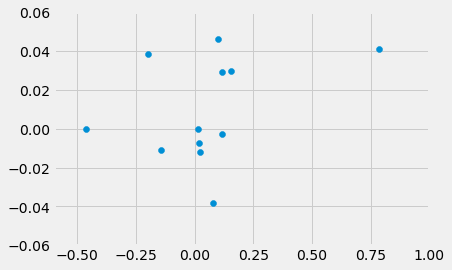

In [22]:
plt.scatter(returns['food_price'],returns['food_production_value'])
plt.show()

### Normalization

In [23]:
date = food_price_production.index

In [24]:
scaler = MinMaxScaler()

In [25]:
food_price_production = scaler.fit_transform(food_price_production)
food_price_production = pd.DataFrame(food_price_production)
food_price_production['date'] = date
food_price_production.set_index('date', inplace=True)
food_price_production.columns = ['food_price', 'food_production_value']
food_price_production.head()

,food_price,food_production_value
date,,
2008-01-01,0.138512,0.000000
2009-01-01,0.000000,0.274272
2010-01-01,0.066530,0.490291
2011-01-01,0.117426,0.199029
2012-01-01,0.019321,0.117314


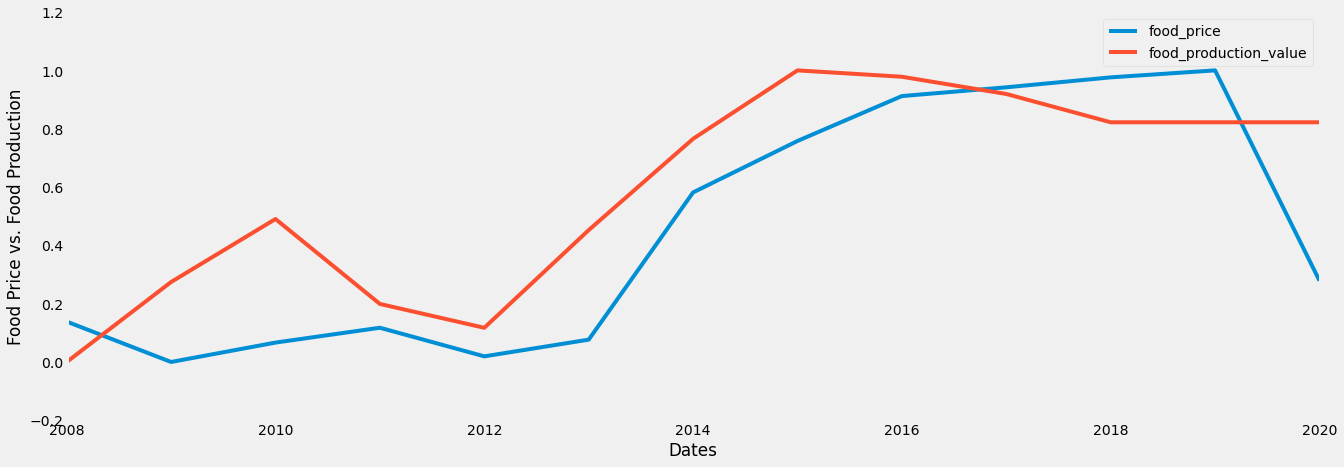

In [27]:
line_ax = food_price_production.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Food Production')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is some positive relation between Food Price and Food Production</span>